In [ ]:
# least noisy timeframe
# the rational behind this test is that retail, institutional and algos trade on the traditional timeframes
# does a timeframe exist with significantly less noise and make it easier to develop trading strategies
# test a very basic strategy to see if a trend is present

import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from Engine.DataTimeseries import DataTimeseries
from Engine.Backtester import Backtester

def generate_trend_filter(ema_length, close_series):
    ema = ta.ema(close_series, length=ema_length)
    ema_dx = ema.diff().fillna(0)
    return np.where(ema_dx > 0, 1, -1)

def test(data):
    final_equities = []
    ema_lengths = np.arange(10, 1000)

    for i in ema_lengths:
        signal = generate_trend_filter(i, data.get_close_prices_series())
        bt = Backtester(
            ohlc=data.get_ohlc_prices(),
            indicies=data.get_indicies(),
            signal=signal,
            timeframe=data.get_timeframe(),
            tick_value=0.5,
            contract_multiplier=2.0,
            initial_equity=100_000,
            slippage_ticks=2,
            commission=0.5
        )

        bt.quick_backtest()
        final_equities.append(bt.final_equity)

    return np.array(final_equities).max()


results = []
for i in range(1, 61):
    data = DataTimeseries('./Data/nq_continous.csv')
    data.resample_data(f'{i}min')
    data.slice(pd.Timestamp(year=2018, month=1, day=1))

    results.append(test(data))

plt.bar(np.arange(0, len(results)), results)


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clea

AssertionError: Invalid resampling timeframe: "60min"


Loading ./Data/nq_continous.csv

Start:     2010-06-07 00:00:00+00:00
End:       2025-11-23 23:59:00+00:00
Timezone:  UTC
Timeframe: 1min
Loaded 5,224,896 clean rows



/Users/newuser/Desktop/Random Coding Crap/Futures/RugbeatunosBacktestingSuite/Engine/DataTimeseries.py:114: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  temp_df = temp_df.resample(timeframe, label='right', closed='left').agg({


2
Bounces: 2892
Penetrations: 8958
Bounce (%): 24.40506329113924
3
Bounces: 2091
Penetrations: 7938
Bounce (%): 20.849536344600658
4
Bounces: 2887
Penetrations: 7268
Bounce (%): 28.42934515017233
5
Bounces: 3468
Penetrations: 7243
Bounce (%): 32.37792923163103
6
Bounces: 3910
Penetrations: 7125
Bounce (%): 35.43271409152696
7
Bounces: 4221
Penetrations: 7036
Bounce (%): 37.496668739451
8
Bounces: 4495
Penetrations: 6896
Bounce (%): 39.46097796506013
9
Bounces: 4584
Penetrations: 6769
Bounce (%): 40.376992865321945
10
Bounces: 4609
Penetrations: 6582
Bounce (%): 41.18488070771155
11
Bounces: 4653
Penetrations: 6466
Bounce (%): 41.847288425218096
12
Bounces: 4621
Penetrations: 6321
Bounce (%): 42.23176750137087
13
Bounces: 4548
Penetrations: 6209
Bounce (%): 42.27944594217718
14
Bounces: 4518
Penetrations: 6096
Bounce (%): 42.566421707179195
15
Bounces: 4485
Penetrations: 5930
Bounce (%): 43.062890062409984
16
Bounces: 4442
Penetrations: 5839
Bounce (%): 43.20591382161268
17
Bounces: 441

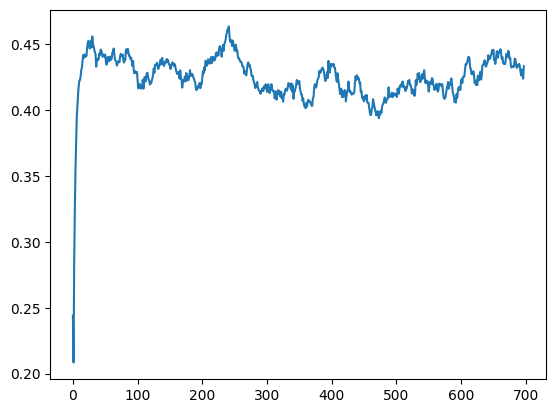

In [18]:
# ewmac bounce probability

import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from Engine.DataTimeseries import DataTimeseries
from Engine.Backtester import Backtester

data = DataTimeseries('./Data/nq_continous.csv')
data.resample_data('1H')
# data.slice(pd.Timestamp(year=2018, month=1, day=1))

ohlc = data.get_ohlc_prices_series()

atr = ta.atr(ohlc['High'], ohlc['Low'], ohlc['Close'], length=200)
bounce_percentages = []
for l in range(2, 700):
    print(l)
    ema = ta.sma(ohlc['Close'], length=l).values
    upper = (ema + atr * 0.5).values
    lower = (ema - atr * 0.5).values

    # classify if price bounces
    # once price crosses one of the emas if it also hits the lower one it counts as a penetration
    # if price cross the ema and then exits it counts as a bounce
    bounces = 0
    penetrations = 0

    inside_range = False
    direction = ''
    closes = ohlc['Close'].values
    for i in range(1, len(ohlc['Close'])):
        prev_close = closes[i - 1]
        close = closes[i]

        if inside_range:
            if direction == 'below':
                if close < lower[i]:
                    bounces += 1
                    inside_range = False
                elif close > upper[i]:
                    penetrations += 1
                    inside_range = False

            elif direction == 'above':
                if close > upper[i]:
                    bounces += 1
                    inside_range = False
                elif close < lower[i]:
                    penetrations += 1
                    inside_range = False
        
        else:
            # close through lower and upper bands in 1 move
            if prev_close < lower[i] and close > upper[i]:
                penetrations += 1
            if prev_close > upper[i] and close < lower[i]:
                penetrations += 1

            # approach from below
            if prev_close < lower[i] and close > lower[i] and not inside_range:
                inside_range = True
                direction = 'below'

            elif prev_close > upper[i] and close < upper[i] and not inside_range:
                inside_range = True
                direction = 'above'

    print(f'Bounces: {bounces}')
    print(f'Penetrations: {penetrations}')
    print(f'Bounce (%): {bounces / (bounces + penetrations) * 100}')
    bounce_percentages.append(bounces / (bounces + penetrations))

plt.plot(np.arange(0, len(bounce_percentages)), bounce_percentages)
